# 02 · Análise exploratória dos precedentes

Este notebook explora os blocos brutos gravados pela auditoria (notebook 01), antes da limpeza, para responder:
1. **Quanto tem de cada tipo**, e quanto ainda vale.
2. **Qual o tamanho dos textos em tokens**, o que define o chunking do notebook 04.
3. **Que ruído o texto bruto carrega:** histórico, notas do TRT-3, origens "(ex-...)" e cabeçalhos. Isso define as regras do notebook 03.
4. **Se a cor do título dos temas bate com o texto da tese.**
5. **Quais normas os precedentes interpretam.**
6. **Se os precedentes que faltaram nas 25 respostas do advogado estão nos documentos.**

### Dados desta etapa

| | Caminho no repositório | Formato | Quantidade | Versionado? |
|---|---|---|---|---|
| Entrada | `data/interim/precedentes/verbetes_brutos.jsonl` | JSONL (um registro JSON por linha) | 1.596 blocos brutos (1.172 súmulas e OJs + 424 blocos de temas) | fora do Git |
| Relatórios | `reports/precedentes/eda/` | CSV e PNG | tokens_por_tipo.csv (3 linhas), ruido_texto_bruto.csv (6), temas_cor_vs_tese.csv (4), artigos_clt_mais_citados.csv (15), cobertura_precedentes_respostas.csv (7) e 2 gráficos | sim |

A EDA não grava dados novos: só lê os blocos brutos e grava relatórios.

In [1]:
from pathlib import Path
import json, sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'src/precedentes').exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
pd.set_option('display.max_colwidth', 120)
pd.set_option('display.width', 250)
pd.set_option('display.max_columns', None)
RAW = ROOT / 'data/raw/precedentes'
BRUTOS = ROOT / 'data/interim/precedentes/verbetes_brutos.jsonl'
SAIDA_JSONL = ROOT / 'data/processed/precedentes/precedentes_tst.jsonl'
REL = ROOT / 'reports/precedentes'

import re
from collections import Counter
brutos = pd.read_json(BRUTOS, lines=True)
verb = brutos[brutos.fonte == 'TRT3_2024'].copy()
tem = brutos[brutos.fonte == 'IRR_2026'].copy()
(REL / 'eda').mkdir(parents=True, exist_ok=True)
print(f'{len(verb)} blocos de súmulas e OJs · {len(tem)} blocos de temas ({tem.codigo.nunique()} temas distintos)')

1172 blocos de súmulas e OJs · 424 blocos de temas (321 temas distintos)


## 1. Volume por tipo e situação preliminar

Aqui a situação é **preliminar**: um verbete conta como cancelado quando o cabeçalho diz "cancelada" ou "cancelamento". Nos temas, ela vem da cor do título. A regra completa fica no notebook 03, que trata casos como o cancelamento de um item só e os verbetes convertidos em outro.

Temas por cor do título: {'azul': 215, 'mostarda': 104, 'vermelho': 2}


,total,canceladas,ativas
serie,,,
OJ Pleno/Órgão Especial,13,0,13
OJ SDC,38,10,28
OJ SBDI-1 transitória,79,3,76
OJ SBDI-2,158,75,83
OJ SBDI-1,421,218,203
Súmulas,463,139,324


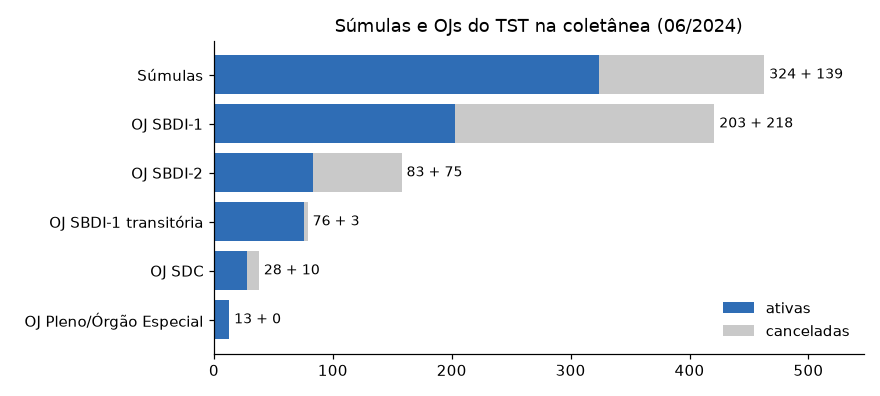

In [2]:
def cabecalho(t):
    return ' '.join(t.split('\n')[:4]).lower()
verb['cancelado_prelim'] = verb.texto_bruto.map(lambda t: bool(re.search(r'\(cancelad|cancelamento mantido', cabecalho(t))))
rotulo = {'SUM': 'Súmulas', 'OJ-SDI1': 'OJ SBDI-1', 'OJ-SDI2': 'OJ SBDI-2', 'OJ-SDI1T': 'OJ SBDI-1 transitória',
          'OJ-SDC': 'OJ SDC', 'OJ-TP/OE': 'OJ Pleno/Órgão Especial'}
vol = verb.groupby('serie').agg(total=('numero', 'size'), canceladas=('cancelado_prelim', 'sum'))
vol['ativas'] = vol.total - vol.canceladas
vol = vol.rename(index=rotulo).sort_values('total')
temas_unicos = tem.drop_duplicates('codigo')
cores = temas_unicos.situacao_cor.value_counts()
display(vol)
print('Temas por cor do título:', cores.to_dict())

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(vol.index, vol.ativas, color='#2f6db5', label='ativas')
ax.barh(vol.index, vol.canceladas, left=vol.ativas, color='#c9c9c9', label='canceladas')
for i, (a, c) in enumerate(zip(vol.ativas, vol.canceladas)):
    ax.text(a + c + 4, i, f'{a} + {c}', va='center', fontsize=9)
ax.set_xlim(0, vol.total.max() * 1.18)
ax.set_title('Súmulas e OJs do TST na coletânea (06/2024)')
ax.legend(loc='lower right', frameon=False)
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(REL / 'eda/volume_por_serie.png', dpi=110)
display(fig); plt.close(fig)

**Leitura:** cerca de um terço dos verbetes já estava cancelado em 2024, a maioria OJs convertidas em súmulas. Eles **não podem** ser entregues como regra. Ficam registrados porque os acórdãos da base de jurisprudência ainda os citam, e uma resposta pode precisar dizer que tal OJ foi cancelada. Nos temas, a maior parte já tem tese fixada, e cerca de um terço está afetado, ainda sem tese.

## 2. Tamanho dos textos em tokens

O tamanho é medido com o tokenizador do BGE-M3, na mesma revisão da busca. Se o modelo não estiver em cache, a medida é estimada pelo número de palavras. O texto bruto ainda inclui o histórico e as notas, por isso também medimos o enunciado sem o histórico. Esse recorte é próximo do que vai para a busca.

Medida: tokens do BAAI/bge-m3 · só verbetes ativos e temas
Acima de 512 tokens: {'OJs': 0, 'Súmulas': 5, 'Temas': 9}


,count,mean,50%,90%,99%,max
grupo,,,,,,
OJs,403.0,126.0,118.0,189.0,266.0,357.0
Súmulas,324.0,139.0,102.0,249.0,549.0,856.0
Temas,321.0,193.0,162.0,289.0,834.0,1797.0


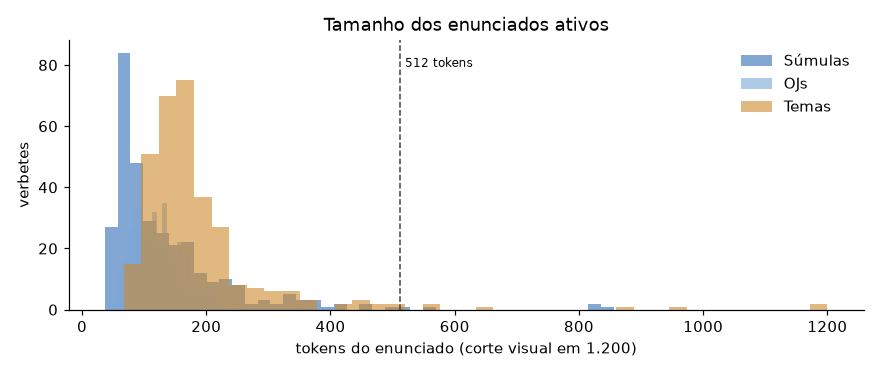

In [3]:
import os
os.environ.setdefault('HF_HUB_OFFLINE', '1')
try:
    from transformers import AutoTokenizer
    from src.integracao.recuperacao import MODELO, REVISAO
    tok = AutoTokenizer.from_pretrained(MODELO, revision=REVISAO, local_files_only=True)
    contar = lambda t: len(tok(t, add_special_tokens=False)['input_ids'])
    medida = f'tokens do {MODELO}'
except Exception as erro:
    contar = lambda t: int(len(t.split()) * 1.6)
    medida = f'estimativa por palavras ({type(erro).__name__})'

def sem_historico(t):
    t = re.split(r'\bHistórico\s*:?', t, maxsplit=1)[0]
    return '\n'.join(l for l in t.split('\n') if not l.strip().startswith('•'))

verb['tokens_bruto'] = verb.texto_bruto.map(contar)
verb['tokens_enunciado'] = verb.texto_bruto.map(sem_historico).map(contar)
tem_u = tem.sort_values('texto_bruto', key=lambda s: s.str.len()).drop_duplicates('codigo', keep='last').copy()
tem_u['tokens_bruto'] = tem_u.texto_bruto.map(contar)
tem_u['tokens_enunciado'] = tem_u.tokens_bruto
ativos = verb[~verb.cancelado_prelim]
tab = pd.concat([ativos.assign(grupo=ativos.serie.map(lambda s: 'Súmulas' if s == 'SUM' else 'OJs')), tem_u.assign(grupo='Temas')])
resumo_tok = tab.groupby('grupo').tokens_enunciado.describe(percentiles=[.5, .9, .99])[['count', 'mean', '50%', '90%', '99%', 'max']].round(0)
print('Medida:', medida, '· só verbetes ativos e temas')
display(resumo_tok)
print('Acima de 512 tokens:', (tab.tokens_enunciado > 512).groupby(tab.grupo).sum().to_dict())
resumo_tok.to_csv(REL / 'eda/tokens_por_tipo.csv', encoding='utf-8')

fig, ax = plt.subplots(figsize=(8, 3.4))
for grupo, cor in [('Súmulas', '#2f6db5'), ('OJs', '#7aa6d8'), ('Temas', '#d08a2e')]:
    ax.hist(tab[tab.grupo == grupo].tokens_enunciado.clip(upper=1200), bins=40, alpha=.6, color=cor, label=grupo)
ax.axvline(512, color='#444', lw=1, ls='--'); ax.text(520, ax.get_ylim()[1] * .9, '512 tokens', fontsize=8)
ax.set_xlabel('tokens do enunciado (corte visual em 1.200)'); ax.set_ylabel('verbetes')
ax.set_title('Tamanho dos enunciados ativos')
ax.legend(frameon=False); ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout(); fig.savefig(REL / 'eda/tokens_por_tipo.png', dpi=110)
display(fig); plt.close(fig)

**Leitura:** os precedentes são **curtos**, e a grande maioria cabe inteira num único trecho. Os acórdãos da base de jurisprudência têm milhares de tokens; um precedente tem, em geral, poucas centenas. Para o chunking (notebook 04), isso significa:
- **um trecho por enunciado** como regra;
- divisão **por item** (I, II, III...) só nas súmulas longas, repetindo o título em cada item;
- os poucos temas longos, com teses de várias partes, são divididos pelos números da tese.

## 3. O que o texto bruto carrega além do enunciado

Contamos em quantos verbetes ativos aparece cada elemento que **não** é a regra. Cada linha da tabela vira uma regra do notebook 03.

In [4]:
padroes = {
    'histórico de redações ("Histórico:")': r'\bHistórico\s*:?',
    'nota remissiva ao TRT-3 (linha com "•")': r'^\s*•',
    'origem do item ("(ex-Súmula...", "(ex-OJ...")': r'\(ex-',
    'enunciado em itens (I -, II -...)': r'(?:^|\s)II\s*[-–]\s',
    'remissão a outro precedente ("Vide", "Tema ... IRR")': r'\(Vide|Tema \d+ IRR',
    'hifenização no fim da linha': r'[a-zà-ú]-\n[a-zà-ú]',
}
ruido = pd.DataFrame([dict(elemento=k, verbetes=int(ativos.texto_bruto.str.contains(p, regex=True, flags=re.M).sum()))
                      for k, p in padroes.items()])
ruido['% dos ativos'] = (100 * ruido.verbetes / len(ativos)).round(1)
display(ruido)
ruido.to_csv(REL / 'eda/ruido_texto_bruto.csv', index=False, encoding='utf-8')
print('\nExemplo (Súmula 60 bruta):\n')
print(verb.set_index('codigo').loc['SUM-60', 'texto_bruto'])


Exemplo (Súmula 60 bruta):

SUM-60 ADICIONAL NOTURNO. INTEGRAÇÃO NO SALÁRIO E PRORROGAÇÃO EM
HORÁRIO DIURNO (incorporada a Orientação Jurisprudencial nº 6 da SBDI-1) - Res.
129/2005, DJ 20, 22 e 25.04.2005
I - O adicional noturno, pago com habitualidade, integra o salário do empregado para todos
os efeitos. (ex-Súmula nº 60 - RA 105/1974, DJ 24.10.1974)
II - Cumprida integralmente a jornada no período noturno e prorrogada esta, devido é também
o adicional quanto às horas prorrogadas. Exegese do art. 73, § 5º, da CLT. (ex-OJ nº 6 da
SBDI-1 - inserida em 25.11.1996)
Histórico:
Súmula mantida - Res. 121/2003, DJ 19, 20 e 21.11.2003
Redação original - RA 105/1974, DJ 24.10.1974
Nº 60 Adicional noturno
O adicional noturno, pago com habitualidade, integra o salário do empregado para todos os efeitos.

• SÚM.  29, OJ-Turmas 24  e TJP 21 TRT3


,elemento,verbetes,% dos ativos
0,"histórico de redações (""Histórico:"")",395,54.3
1,"nota remissiva ao TRT-3 (linha com ""•"")",170,23.4
2,"origem do item (""(ex-Súmula..."", ""(ex-OJ..."")",146,20.1
3,"enunciado em itens (I -, II -...)",85,11.7
4,"remissão a outro precedente (""Vide"", ""Tema ... IRR"")",11,1.5
5,hifenização no fim da linha,12,1.7


**Leitura:** o exemplo da Súmula 60 mostra o problema. Além do enunciado, o bloco traz:
- a **redação original**, que já não vale;
- uma nota do TRT-3 ("SÚM. 29, OJ-Turmas 24...").

Se o histórico entrar na busca, o modelo pode citar uma redação revogada como se fosse a atual. Por isso, no notebook 03:
- o histórico vai para um campo à parte, fora do texto de busca;
- as notas do TRT-3 também vão para um campo à parte;
- as origens "(ex-...)" saem do texto de busca e ficam no texto oficial.

## 4. Temas: a cor do título confere com a tese?

A situação do tema pode ser lida de duas formas: pela cor do título ou pelo texto da tese ("Ainda não fixada", "Superada"). Comparamos as duas para ver qual é mais confiável.

In [5]:
def sit_tese(t):
    m = re.search(r'^Tese\s*:\s*(.*)$', t, re.M)
    if not m or m.group(1).lower().startswith('ainda não fixada'):
        return 'sem tese'
    return 'superada' if m.group(1).lower().startswith('superada') else 'tese fixada'
tem_u['pela_tese'] = tem_u.texto_bruto.map(sit_tese)
cruz = pd.crosstab(tem_u.situacao_cor, tem_u.pela_tese, margins=True, margins_name='total')
display(cruz)
diverg = tem_u[(tem_u.situacao_cor == 'mostarda') & (tem_u.pela_tese == 'tese fixada')]
print('Cor mostarda, mas com tese no texto:', ', '.join(diverg.codigo))
cruz.to_csv(REL / 'eda/temas_cor_vs_tese.csv', encoding='utf-8')
oc = tem.groupby('codigo').size()
print(f'\nOcorrências por tema no índice: média {oc.mean():.1f} · máximo {oc.max()} · temas com aviso de suspensão: '
      f'{tem.groupby("codigo").texto_bruto.apply(lambda s: s.str.contains("AVISO").any()).sum()}')
assuntos = tem[~tem.assunto.fillna('').str.startswith('INCIDENTES')].assunto.value_counts().head(12)
display(assuntos.rename('temas').to_frame())

Cor mostarda, mas com tese no texto: IRR-24, IRR-91, IRR-27, IRR-39, IRR-32

Ocorrências por tema no índice: média 1.3 · máximo 4 · temas com aviso de suspensão: 45


pela_tese,sem tese,superada,tese fixada,total
situacao_cor,,,,
azul,0,0,216,216
mostarda,98,0,5,103
vermelho,0,2,0,2
total,98,2,221,321


,temas
assunto,
"HORAS EXTRAS, HORAS IN ITINERE , INTERVALO, DIVISOR ALTERAÇÃO (JORNADA DE TRABALHO)",34
"DIREITO PROCESSUAL (PRESSUPOSTOS, REQUISITOS, EXTINÇÃO, CABIMENTO, PROVAS, NULIDADES)",28
DANO MORAL E PATRIMONIAL / RESPONSABILIDADE CIVIL,27
DESPEDIDA / DEMISSÃO / DISPENSA (RESCISÃO CONTRATUAL),25
SINDICATOS / NEGOCIAÇÃO COLETIVA / ACORDO COLETIVO,22
BANCÁRIOS,20
PRESCRIÇÃO,19
ADICIONAL DE PERICULOSIDADE,16
ADICIONAL DE INSALUBRIDADE,15


**Leitura:** a cor e o texto concordam em quase todos os temas. A exceção são poucos temas em mostarda que já trazem a tese escrita, provavelmente julgados depois de a cor ser atribuída. Por isso, **o texto da tese decide a situação** e a cor serve como conferência.

Os assuntos com mais temas são justamente os mais frequentes nas perguntas:
- horas extras e jornada;
- negociação coletiva, muito por causa do Tema 1.046 do STF;
- adicionais;
- dispensa.

## 5. Que normas os precedentes interpretam

Contamos os artigos da CLT citados nos enunciados ativos e nas referências dos temas. Essa ligação permite, mais adiante, buscar o precedente pelo artigo da lei que a pergunta menciona.

In [6]:
ART_CLT = re.compile(r'art(?:igo)?s?\.?\s*(\d{1,3}(?:-[A-Z])?)(?:[^.;]{0,40}?)\s*,?\s*da CLT|CLT\s*[:,]?\s*arts?\.?\s*(\d{1,3}(?:-[A-Z])?)', re.I)
def artigos(t):
    return {a or b for a, b in ART_CLT.findall(t)}
textos = pd.concat([ativos.texto_bruto.map(sem_historico), tem_u.texto_bruto])
cont = Counter(a for t in textos for a in artigos(t))
top = pd.DataFrame(cont.most_common(15), columns=['art. da CLT', 'precedentes'])
display(top.T)
print(f'Precedentes ativos que citam ao menos um artigo da CLT: {sum(bool(artigos(t)) for t in textos)} de {len(textos)}')
top.to_csv(REL / 'eda/artigos_clt_mais_citados.csv', index=False, encoding='utf-8')
reafirma = tem_u.texto_bruto.str.contains(r'Reafirmação|reafirma', case=False).sum()
print(f'Temas que reafirmam súmula ou OJ (reafirmação de jurisprudência): {reafirma}')

Precedentes ativos que citam ao menos um artigo da CLT: 307 de 1048
Temas que reafirmam súmula ou OJ (reafirmação de jurisprudência): 55


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
art. da CLT,224,477,193,468,896,58,71,899,62,789,894,195,457,461,73
precedentes,18,17,15,12,11,9,9,8,8,8,6,6,6,5,5


## 6. Os precedentes que faltaram nas 25 respostas estão aqui?

O notebook 00 lista os precedentes que o advogado revisor apontou como decisivos nas respostas reprovadas. Conferimos se cada um está nos documentos recebidos e se está ativo. As perguntas não aparecem aqui, porque são protegidas.

In [7]:
esperados = [('P6', 'SUM-338', 'I'), ('P7', 'SUM-276', None), ('P10', 'SUM-378', 'II'), ('P11', 'SUM-6', 'VIII'),
             ('P24', 'SUM-60', 'II'), ('P3', 'SUM-45', None)]
idx = verb.set_index('codigo')
linhas = []
for p, cod, item in esperados:
    t = idx.texto_bruto.get(cod, '')
    linhas.append(dict(resposta=p, precedente=cod + (f', {item}' if item else ''), encontrado=bool(t),
                       ativo=bool(t) and not idx.cancelado_prelim.get(cod, True),
                       item_presente=(item is None) or bool(re.search(rf'(?:^|\s){item}\s*[-–]', t))))
revista = tem_u[tem_u.texto_bruto.str.contains(r'revista (?:visual|íntima|de bolsas|pessoal)|pertences', case=False)]
for _, r in revista.iterrows():
    linhas.append(dict(resposta='P23', precedente=r.codigo, encontrado=True, ativo=r.pela_tese == 'tese fixada', item_presente=True))
cob = pd.DataFrame(linhas)
display(cob)
cob.to_csv(REL / 'eda/cobertura_precedentes_respostas.csv', index=False, encoding='utf-8')
print('Fora desta base: P4 (ADI 5766 do STF) fica para a etapa do STF.')

Fora desta base: P4 (ADI 5766 do STF) fica para a etapa do STF.


,resposta,precedente,encontrado,ativo,item_presente
0,P6,"SUM-338, I",True,True,True
1,P7,SUM-276,True,True,True
2,P10,"SUM-378, II",True,True,True
3,P11,"SUM-6, VIII",True,True,True
4,P24,"SUM-60, II",True,True,True
5,P3,SUM-45,True,True,True
6,P23,IRR-58,True,True,True


**Leitura:** os precedentes das respostas reprovadas estão nos documentos, ativos e com o item certo:
- Súmula 338, I;
- Súmula 276;
- Súmula 378, II;
- Súmula 6, VIII;
- Súmula 60, II;
- Súmula 45.

A tese sobre revista de pertences está no índice de IRR. Só a P4, que depende de uma decisão do STF, fica de fora. Assim, a base cobre 7 dos 8 casos em que faltou o precedente.

## Conclusões para a limpeza (notebook 03)

1. **Situação:** é preciso uma regra mais completa que a preliminar, que trate cancelamento de item, conversão em outro verbete e quarentena dos cancelamentos noticiados.
2. **Texto de busca:** só o enunciado vigente, sem o histórico, sem as notas do TRT-3 e sem as origens "(ex-...)".
3. **Itens:** separar os itens (I, II...) para o chunking.
4. **Temas:** um registro por tema, juntando as repetições. A situação vem da tese, e a cor serve de conferência. Os avisos de suspensão ficam num campo à parte.
5. **Tamanho:** os textos são curtos, e o chunking pode usar um trecho por enunciado ou por item.